### ML

In [72]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from lazypredict.Supervised import LazyRegressor
from sklearn.model_selection import train_test_split
from sklearn import datasets
from sklearn.utils import shuffle
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV,StratifiedKFold
import seaborn as sns

In [73]:
df = pd.read_csv("mart_customer_risk_value.csv")

In [74]:
df

,SK_ID_CURR,TARGET,credit_income_ratio,annuity_income_ratio,age_years,employment_years,credit_goods_ratio,income_per_person,ext_source_avg,bureau_total_credit,...,previous_max_credit,previous_avg_application,previous_avg_annuity,previous_avg_payment_count,previous_avg_down_payment,previous_avg_down_payment_rate,previous_last_decision_days,previous_cash_loan_count,previous_consumer_loan_count,previous_insured_ratio
0,293023,0,4.964571,0.512857,65.112329,NaN,1.158400,15750.000,0.647891,2.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,316616,0,7.529600,0.385900,51.438356,NaN,1.158400,18000.000,0.539636,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,146397,0,1.831390,0.091570,33.534247,0.594521,1.000000,18428.625,0.381567,5.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,349305,0,4.660126,0.124947,53.301370,5.720548,1.330000,21405.000,0.499968,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,361016,0,1.415000,0.141400,59.457534,23.400000,1.132000,22500.000,0.455673,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70193,367376,0,1.437600,0.078350,30.282192,3.780822,1.198000,120000.000,0.435461,3.0,...,450000.0,71768.734615,9723.323077,9.692308,8666.619231,0.140721,-850.0,1.0,11.0,0.307692
70194,370142,0,4.232320,0.219533,31.616438,11.767123,1.058080,84375.000,0.732153,3.0,...,450000.0,99098.625000,9775.837500,15.583333,3853.125000,0.035920,-292.0,1.0,10.0,0.250000
70195,252828,0,1.814800,0.058830,32.550685,6.876712,1.396000,150000.000,0.369023,3.0,...,983299.5,220278.535714,19097.588571,21.428571,2435.464286,0.029947,-52.0,8.0,5.0,0.571429
70196,267150,0,4.472115,0.160615,55.273973,NaN,1.211198,117000.000,0.485940,22.0,...,652500.0,132800.464286,8141.059286,17.000000,551.250000,0.029857,-618.0,4.0,10.0,0.214286


In [75]:
df.shape

(70198, 65)

In [76]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70198 entries, 0 to 70197
Data columns (total 65 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   SK_ID_CURR                       70198 non-null  int64  
 1   TARGET                           70198 non-null  int64  
 2   credit_income_ratio              70198 non-null  float64
 3   annuity_income_ratio             70196 non-null  float64
 4   age_years                        70198 non-null  float64
 5   employment_years                 57161 non-null  float64
 6   credit_goods_ratio               70122 non-null  float64
 7   income_per_person                70196 non-null  float64
 8   ext_source_avg                   70158 non-null  float64
 9   bureau_total_credit              60497 non-null  float64
 10  bureau_active_credit_count       60497 non-null  float64
 11  bureau_closed_credit_count       60497 non-null  float64
 12  bureau_total_credi

In [77]:
df.columns

Index(['SK_ID_CURR', 'TARGET', 'credit_income_ratio', 'annuity_income_ratio',
       'age_years', 'employment_years', 'credit_goods_ratio',
       'income_per_person', 'ext_source_avg', 'bureau_total_credit',
       'bureau_active_credit_count', 'bureau_closed_credit_count',
       'bureau_total_credit_amount', 'bureau_total_debt', 'bureau_avg_credit',
       'bureau_max_credit', 'bureau_total_overdue_amount',
       'bureau_max_overdue', 'bureau_overdue_credit_count',
       'bureau_late_month_count', 'bureau_serious_late_month_count',
       'bureau_credit_prolong_count', 'bureau_most_recent_credit_days',
       'cc_total_prev_apps', 'cc_amt_balance_mean', 'cc_amt_balance_max',
       'cc_credit_limit_max', 'cc_amt_drawings_sum', 'cc_max_dpd',
       'cc_min_payment_missed_sum', 'instal_total_records',
       'instal_amt_installment_sum', 'instal_amt_payment_sum',
       'instal_days_late_mean', 'instal_days_late_max', 'instal_days_late_sum',
       'instal_underpaid_total_sum', 'tot

In [78]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SK_ID_CURR,70198.0,278002.865495,102657.063506,100007.000000,189246.500000,277793.000000,366593.250000,456253.000000
TARGET,70198.0,0.079646,0.270747,0.000000,0.000000,0.000000,0.000000,1.000000
credit_income_ratio,70198.0,4.006562,3.032878,0.004808,2.000000,3.169600,5.130484,84.736842
annuity_income_ratio,70196.0,0.182397,0.110408,0.000224,0.107702,0.156308,0.229692,1.875965
age_years,70198.0,43.500857,12.071977,21.030137,33.460274,41.860274,53.964384,69.120548
...,...,...,...,...,...,...,...,...
previous_avg_down_payment_rate,65426.0,0.050534,0.068990,0.000000,0.000000,0.028233,0.072971,0.871273
previous_last_decision_days,65426.0,-492.122535,550.676232,-2922.000000,-611.000000,-306.000000,-148.000000,-2.000000
previous_cash_loan_count,65426.0,2.123024,3.242154,0.000000,0.000000,1.000000,3.000000,58.000000
previous_consumer_loan_count,65426.0,2.162810,1.840053,0.000000,1.000000,2.000000,3.000000,42.000000


In [79]:
df.duplicated().sum()

np.int64(0)

In [80]:
df["TARGET"].value_counts()

TARGET
0    64607
1     5591
Name: count, dtype: int64

In [81]:
df["TARGET"].value_counts(normalize=True) * 100

TARGET
0    92.035386
1     7.964614
Name: proportion, dtype: float64

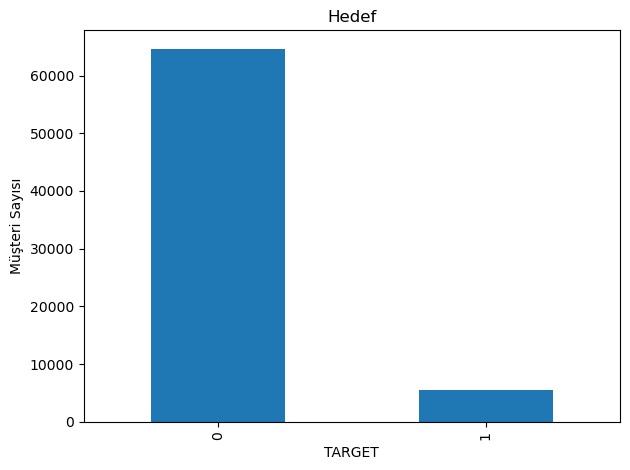

In [82]:
df["TARGET"].value_counts().sort_index().plot(
    kind="bar",
    xlabel="TARGET",
    ylabel="Müşteri Sayısı",
    title="Hedef"
)
plt.tight_layout()
plt.show()

In [83]:
df.isnull().sum().sort_values(ascending=False).head(20)

cc_credit_limit_max           58806
cc_amt_balance_max            57763
cc_total_prev_apps            57763
cc_min_payment_missed_sum     57763
cc_max_dpd                    57763
cc_amt_drawings_sum           57763
cc_amt_balance_mean           57763
instal_underpaid_total_sum    52820
instal_days_late_sum          52820
instal_days_late_max          52820
instal_days_late_mean         52820
instal_amt_installment_sum    52820
instal_total_records          52820
instal_amt_payment_sum        52820
max_dpd                       45463
def_delayed_record_count      45463
delayed_record_ratio          45463
delayed_record_count          45463
pos_contract_count            45463
total_pos_records             45463
dtype: int64

In [84]:
missing_ratio = (
    df.isnull().mean() * 100
).sort_values(ascending=False)

missing_ratio.head(20)

cc_credit_limit_max           83.771617
cc_amt_balance_max            82.285820
cc_total_prev_apps            82.285820
cc_min_payment_missed_sum     82.285820
cc_max_dpd                    82.285820
cc_amt_drawings_sum           82.285820
cc_amt_balance_mean           82.285820
instal_underpaid_total_sum    75.244309
instal_days_late_sum          75.244309
instal_days_late_max          75.244309
instal_days_late_mean         75.244309
instal_amt_installment_sum    75.244309
instal_total_records          75.244309
instal_amt_payment_sum        75.244309
max_dpd                       64.763953
def_delayed_record_count      64.763953
delayed_record_ratio          64.763953
delayed_record_count          64.763953
pos_contract_count            64.763953
total_pos_records             64.763953
dtype: float64

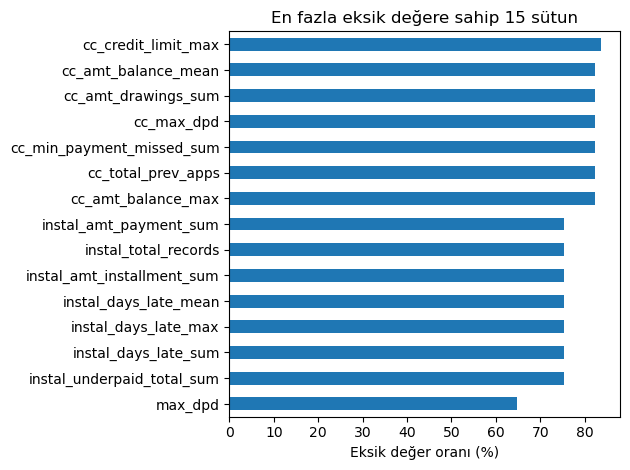

In [85]:
missing_top = missing_ratio.head(15)

missing_top.sort_values().plot(
    kind="barh",
    xlabel="Eksik değer oranı (%)",
    title="En fazla eksik değere sahip 15 sütun"
)

plt.tight_layout()
plt.show()

In [86]:
df_copy = df

In [87]:
df_copy

,SK_ID_CURR,TARGET,credit_income_ratio,annuity_income_ratio,age_years,employment_years,credit_goods_ratio,income_per_person,ext_source_avg,bureau_total_credit,...,previous_max_credit,previous_avg_application,previous_avg_annuity,previous_avg_payment_count,previous_avg_down_payment,previous_avg_down_payment_rate,previous_last_decision_days,previous_cash_loan_count,previous_consumer_loan_count,previous_insured_ratio
0,293023,0,4.964571,0.512857,65.112329,NaN,1.158400,15750.000,0.647891,2.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,316616,0,7.529600,0.385900,51.438356,NaN,1.158400,18000.000,0.539636,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,146397,0,1.831390,0.091570,33.534247,0.594521,1.000000,18428.625,0.381567,5.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,349305,0,4.660126,0.124947,53.301370,5.720548,1.330000,21405.000,0.499968,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,361016,0,1.415000,0.141400,59.457534,23.400000,1.132000,22500.000,0.455673,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70193,367376,0,1.437600,0.078350,30.282192,3.780822,1.198000,120000.000,0.435461,3.0,...,450000.0,71768.734615,9723.323077,9.692308,8666.619231,0.140721,-850.0,1.0,11.0,0.307692
70194,370142,0,4.232320,0.219533,31.616438,11.767123,1.058080,84375.000,0.732153,3.0,...,450000.0,99098.625000,9775.837500,15.583333,3853.125000,0.035920,-292.0,1.0,10.0,0.250000
70195,252828,0,1.814800,0.058830,32.550685,6.876712,1.396000,150000.000,0.369023,3.0,...,983299.5,220278.535714,19097.588571,21.428571,2435.464286,0.029947,-52.0,8.0,5.0,0.571429
70196,267150,0,4.472115,0.160615,55.273973,NaN,1.211198,117000.000,0.485940,22.0,...,652500.0,132800.464286,8141.059286,17.000000,551.250000,0.029857,-618.0,4.0,10.0,0.214286


In [88]:
y = df_copy["TARGET"]

In [89]:
X = df_copy.drop(columns=["TARGET","SK_ID_CURR"])

In [90]:
X.dtypes.value_counts()

float64    63
Name: count, dtype: int64

In [91]:
X.select_dtypes(
    include=["object","category","string"]
).columns

Index([], dtype='object')

In [92]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3,stratify=y,random_state=42)

In [93]:
#eğitim özelliklerşi
X_train.shape

(49138, 63)

In [94]:
#test özellikleri
X_test.shape

(21060, 63)

In [95]:
#eğitim hedefi
y_train.shape

(49138,)

In [96]:
#test hedefi
y_test.shape

(21060,)

In [97]:
imputer = SimpleImputer(strategy="median")

In [98]:
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

In [99]:
model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

In [100]:
model.fit(X_train_imputed,y_train)

/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [101]:
model = LogisticRegression()

In [102]:
penalty = ["l1","l2","elasticnet"]
c_values = [100,10,1,0.1,0.01]
solver=["newton-cg","lbfgs","s","sag","saga","newton-cholesky"]

In [103]:
params = [
    # 1. Sadece 'l2' destekleyen solver'lar
    {
        'solver': ['newton-cg', 'lbfgs', 'sag', 'newton-cholesky'],
        'penalty': ['l2'],
        'C': [100, 10, 1, 0.1, 0.01]
    },
    # 2. Hem 'l1' hem 'l2' destekleyen solver'lar
    {
        'solver': ['liblinear', 'saga'],
        'penalty': ['l1', 'l2'],
        'C': [100, 10, 1, 0.1, 0.01]
    }
]

In [104]:
params

[{'solver': ['newton-cg', 'lbfgs', 'sag', 'newton-cholesky'],
  'penalty': ['l2'],
  'C': [100, 10, 1, 0.1, 0.01]},
 {'solver': ['liblinear', 'saga'],
  'penalty': ['l1', 'l2'],
  'C': [100, 10, 1, 0.1, 0.01]}]

In [105]:
cv = StratifiedKFold()

In [106]:
grid = GridSearchCV(
    estimator=model,
    param_grid=params,
    cv=cv,
    scoring="accuracy",
    error_score='raise', 
    n_jobs=-1
)

In [107]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

# 1. Önce Pipeline'ı tanımlayın (İçinde hem imputer hem model var)
pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')), # Eksik verileri ortalama ile doldurur
    ('model', LogisticRegression())
])

# 2. Parametrelerin başına 'model__' öneki eklediğimizden emin olun
params = [
    {
        'model__solver': ['newton-cg', 'lbfgs', 'sag', 'newton-cholesky'],
        'model__penalty': ['l2'],
        'model__C': [100, 10, 1, 0.1, 0.01]
    },
    {
        'model__solver': ['liblinear', 'saga'],
        'model__penalty': ['l1', 'l2'],
        'model__C': [100, 10, 1, 0.1, 0.01]
    }
]

# 3. GridSearchCV içine estimator olarak model DEĞİL, 'pipe' verin!
grid = GridSearchCV(
    estimator=pipe,          # <-- BURASI KESİNLİKLE 'pipe' OLMALI
    param_grid=params,
    cv=cv,
    scoring="accuracy",
    error_score='raise',
    n_jobs=-1
)

# 4. Modeli eğitin
grid.fit(X_train, y_train)

/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also 

,estimator,Pipeline(step...egression())])
,param_grid,"[{'model__C': [100, 10, ...], 'model__penalty': ['l2'], 'model__solver': ['newton-cg', 'lbfgs', ...]}, {'model__C': [100, 10, ...], 'model__penalty': ['l1', 'l2'], 'model__solver': ['liblinear', 'saga']}]"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo...shuffle=False)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,'raise'
,return_train_score,False
,missing_values,nan


In [108]:
grid.best_estimator_

,steps,"[('imputer', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'mean'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,penalty,'l1'


In [109]:
grid.best_params_

{'model__C': 10, 'model__penalty': 'l1', 'model__solver': 'liblinear'}

In [110]:
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    (
        "classifier",
        LogisticRegression(
            penalty="l2",
            C=1.0,
            solver="lbfgs",
            max_iter=1000,
            class_weight=None,
            random_state=42
        )
    )
])

In [111]:
model.fit(X_train, y_train)

,steps,"[('imputer', ...), ('scaler', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,copy,True


In [112]:
y_pred = model.predict(X_test)

y_proba = model.predict_proba(X_test)[:, 1]

In [113]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("Accuracy:", accuracy_score(y_test, y_pred))

print(
    "Precision:",
    precision_score(y_test, y_pred, zero_division=0)
)

print(
    "Recall:",
    recall_score(y_test, y_pred, zero_division=0)
)

print(
    "F1-score:",
    f1_score(y_test, y_pred, zero_division=0)
)

print(
    "ROC-AUC:",
    roc_auc_score(y_test, y_proba)
)

Accuracy: 0.9203703703703704
Precision: 0.5
Recall: 0.01490757304710793
F1-score: 0.02895193977996526
ROC-AUC: 0.7370046617949058


In [114]:
print("Eğitim verisi dağılımı:")
print(y_train.value_counts())
print(y_train.value_counts(normalize=True) * 100)

print("\nTest verisi dağılımı:")
print(y_test.value_counts())
print(y_test.value_counts(normalize=True) * 100)

Eğitim verisi dağılımı:
TARGET
0    45224
1     3914
Name: count, dtype: int64
TARGET
0    92.034678
1     7.965322
Name: proportion, dtype: float64

Test verisi dağılımı:
TARGET
0    19383
1     1677
Name: count, dtype: int64
TARGET
0    92.037037
1     7.962963
Name: proportion, dtype: float64


In [115]:
from sklearn.metrics import confusion_matrix, classification_report

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Confusion Matrix:
[[19358    25]
 [ 1652    25]]

Classification Report:
              precision    recall  f1-score   support

           0       0.92      1.00      0.96     19383
           1       0.50      0.01      0.03      1677

    accuracy                           0.92     21060
   macro avg       0.71      0.51      0.49     21060
weighted avg       0.89      0.92      0.88     21060



In [116]:
model.set_params(
    classifier__class_weight="balanced"
)

model.fit(X_train, y_train)

y_pred_balanced = model.predict(X_test)
y_proba_balanced = model.predict_proba(X_test)[:, 1]

In [117]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_balanced))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_balanced,
    zero_division=0
))

print(
    "ROC-AUC:",
    roc_auc_score(y_test, y_proba_balanced)
)

Confusion Matrix:
[[13383  6000]
 [  556  1121]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.69      0.80     19383
           1       0.16      0.67      0.25      1677

    accuracy                           0.69     21060
   macro avg       0.56      0.68      0.53     21060
weighted avg       0.90      0.69      0.76     21060

ROC-AUC: 0.7370171520691815


In [118]:
from sklearn.model_selection import train_test_split

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

model.fit(X_fit, y_fit)

# TARGET=1 olma olasılıkları
y_val_proba = model.predict_proba(X_val)[:, 1]


In [119]:
import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

thresholds = [0.20, 0.30, 0.40, 0.50, 0.60]

results = []

for threshold in thresholds:
    y_val_pred = (y_val_proba >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, y_val_pred),
        "Precision": precision_score(
            y_val, y_val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_val_pred, zero_division=0
        ),
        "F1": f1_score(
            y_val, y_val_pred, zero_division=0
        )
    })

results_df = pd.DataFrame(results)

print(results_df.round(3))

   Threshold  Accuracy  Precision  Recall     F1
0        0.2     0.204      0.089   0.977  0.164
1        0.3     0.383      0.107   0.918  0.192
2        0.4     0.547      0.127   0.798  0.219
3        0.5     0.687      0.155   0.658  0.251
4        0.6     0.793      0.194   0.506  0.280


In [120]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

thresholds = np.arange(0.40, 0.751, 0.025)
results = []

for threshold in thresholds:
    y_val_pred = (y_val_proba >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, y_val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_val_pred, zero_division=0
        ),
        "F1": f1_score(
            y_val, y_val_pred, zero_division=0
        )
    })

threshold_results = pd.DataFrame(results)

print(
    threshold_results
    .sort_values("F1", ascending=False)
    .head(10)
    .round(3)
)

    Threshold  Precision  Recall     F1
10      0.650      0.218   0.429  0.289
9       0.625      0.206   0.470  0.287
8       0.600      0.194   0.506  0.280
11      0.675      0.224   0.373  0.280
13      0.725      0.261   0.300  0.279
7       0.575      0.187   0.552  0.279
14      0.750      0.289   0.267  0.278
12      0.700      0.239   0.331  0.277
6       0.550      0.177   0.596  0.272
5       0.525      0.168   0.635  0.265


In [121]:
# Eğitim ve doğrulama verilerini birleştir
X_train_final = pd.concat([X_fit, X_val])
y_train_final = pd.concat([y_fit, y_val])

# Modeli aynı ayarlarla yeniden eğit
model.fit(X_train_final, y_train_final)

# Test olasılıklarını üret
y_test_proba = model.predict_proba(X_test)[:, 1]

# Doğrulama verisinde seçtiğimiz eşik
chosen_threshold = 0.65

# Eşik ile sınıflandırma yap
y_test_pred = (
    y_test_proba >= chosen_threshold
).astype(int)


In [122]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("Test Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nTest Classification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    zero_division=0
))

print(
    "Test ROC-AUC:",
    roc_auc_score(y_test, y_test_proba)
)

Test Confusion Matrix:
[[16743  2640]
 [  980   697]]

Test Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.86      0.90     19383
           1       0.21      0.42      0.28      1677

    accuracy                           0.83     21060
   macro avg       0.58      0.64      0.59     21060
weighted avg       0.89      0.83      0.85     21060

Test ROC-AUC: 0.7370171520691815


In [123]:
df.head(5)

,SK_ID_CURR,TARGET,credit_income_ratio,annuity_income_ratio,age_years,employment_years,credit_goods_ratio,income_per_person,ext_source_avg,bureau_total_credit,...,previous_max_credit,previous_avg_application,previous_avg_annuity,previous_avg_payment_count,previous_avg_down_payment,previous_avg_down_payment_rate,previous_last_decision_days,previous_cash_loan_count,previous_consumer_loan_count,previous_insured_ratio
0,293023,0,4.964571,0.512857,65.112329,NaN,1.1584,15750.000,0.647891,2.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,316616,0,7.529600,0.385900,51.438356,NaN,1.1584,18000.000,0.539636,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,146397,0,1.831390,0.091570,33.534247,0.594521,1.0000,18428.625,0.381567,5.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,349305,0,4.660126,0.124947,53.301370,5.720548,1.3300,21405.000,0.499968,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,361016,0,1.415000,0.141400,59.457534,23.400000,1.1320,22500.000,0.455673,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


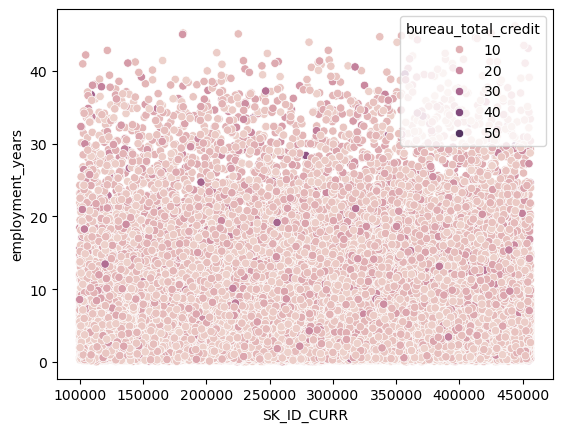

In [124]:
sns.scatterplot(x=df["SK_ID_CURR"],y=df["employment_years"],hue=df["bureau_total_credit"])
plt.show()

In [127]:
print("Veri seti boyutu:", df.shape)

print("\nModelin kullanacağı özellik sayısı:", X.shape[1])

print("\nHedef değişken dağılımı:")
print(y.value_counts())
print("\nHedef Test değişken dağılımı:")
print(y_test.value_counts())

print("\nKullanılan özellikler:")
print(X.columns.tolist())

Veri seti boyutu: (70198, 65)

Modelin kullanacağı özellik sayısı: 63

Hedef değişken dağılımı:
TARGET
0    64607
1     5591
Name: count, dtype: int64

Hedef Test değişken dağılımı:
TARGET
0    19383
1     1677
Name: count, dtype: int64

Kullanılan özellikler:
['credit_income_ratio', 'annuity_income_ratio', 'age_years', 'employment_years', 'credit_goods_ratio', 'income_per_person', 'ext_source_avg', 'bureau_total_credit', 'bureau_active_credit_count', 'bureau_closed_credit_count', 'bureau_total_credit_amount', 'bureau_total_debt', 'bureau_avg_credit', 'bureau_max_credit', 'bureau_total_overdue_amount', 'bureau_max_overdue', 'bureau_overdue_credit_count', 'bureau_late_month_count', 'bureau_serious_late_month_count', 'bureau_credit_prolong_count', 'bureau_most_recent_credit_days', 'cc_total_prev_apps', 'cc_amt_balance_mean', 'cc_amt_balance_max', 'cc_credit_limit_max', 'cc_amt_drawings_sum', 'cc_max_dpd', 'cc_min_payment_missed_sum', 'instal_total_records', 'instal_amt_installment_sum', 

In [128]:
model

,steps,"[('imputer', ...), ('scaler', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,copy,True


In [129]:
import joblib
joblib.dump(model,"credit_risk_model.pkl")

['credit_risk_model.pkl']

In [130]:
model = joblib.dump(model,"credit_risk_model.pkl")

In [131]:
model

['credit_risk_model.pkl']

In [141]:
import pandas as pd

feature_names = X.columns.tolist()

new_customer = pd.DataFrame(
    [[0] * len(feature_names)],
    columns=feature_names
)

risk_probability = model.predict_proba(new_customer)[:, 1][0]

print("Tahmini ödeme güçlüğü olasılığı:", risk_probability)

AttributeError: 'list' object has no attribute 'predict_proba'

In [142]:
print(type(model))

<class 'list'>


In [143]:
import joblib

model = joblib.load("credit_risk_model.pkl")

print(type(model))

<class 'sklearn.pipeline.Pipeline'>


In [144]:
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

model.fit(X_train, y_train)

print("Model yeniden eğitildi.")
print(type(model))

Model yeniden eğitildi.
<class 'sklearn.pipeline.Pipeline'>


In [145]:
feature_names = X.columns.tolist()

new_customer = pd.DataFrame(
    [[0] * len(feature_names)],
    columns=feature_names
)

risk_probability = model.predict_proba(new_customer)[0, 1]

print("Tahmini ödeme güçlüğü olasılığı:", risk_probability)
print("Yüzde:", round(risk_probability * 100, 2))

Tahmini ödeme güçlüğü olasılığı: 0.7077326911207574
Yüzde: 70.77


In [146]:
print(type(model))

<class 'sklearn.pipeline.Pipeline'>


In [147]:
import pandas as pd

feature_names = X.columns.tolist()

new_customer = pd.DataFrame(
    [[0] * len(feature_names)],
    columns=feature_names
)

risk_probability = model.predict_proba(new_customer)[:, 1][0]

print("Tahmini ödeme güçlüğü olasılığı:", risk_probability)

Tahmini ödeme güçlüğü olasılığı: 0.7077326911207574


In [149]:
for column in X.columns:
    print(column)

credit_income_ratio
annuity_income_ratio
age_years
employment_years
credit_goods_ratio
income_per_person
ext_source_avg
bureau_total_credit
bureau_active_credit_count
bureau_closed_credit_count
bureau_total_credit_amount
bureau_total_debt
bureau_avg_credit
bureau_max_credit
bureau_total_overdue_amount
bureau_max_overdue
bureau_overdue_credit_count
bureau_late_month_count
bureau_serious_late_month_count
bureau_credit_prolong_count
bureau_most_recent_credit_days
cc_total_prev_apps
cc_amt_balance_mean
cc_amt_balance_max
cc_credit_limit_max
cc_amt_drawings_sum
cc_max_dpd
cc_min_payment_missed_sum
instal_total_records
instal_amt_installment_sum
instal_amt_payment_sum
instal_days_late_mean
instal_days_late_max
instal_days_late_sum
instal_underpaid_total_sum
total_pos_records
pos_contract_count
delayed_record_count
delayed_record_ratio
max_dpd
def_delayed_record_count
def_delayed_record_ratio
max_dpd_def
completed_contract_count
completed_contract_ratio
previous_application_count
previous_app

In [150]:

sample_customer = X_test.iloc[[0]]

probability = model.predict_proba(sample_customer)[0, 1]

print(f"Ödeme güçlüğü tahmini: %{probability * 100:.2f}")

actual_result = y_test.iloc[0]

print("Gerçek TARGET değeri:", actual_result)


Ödeme güçlüğü tahmini: %43.25
Gerçek TARGET değeri: 0


In [151]:

application_features = [
    "credit_income_ratio",
    "annuity_income_ratio",
    "age_years",
    "employment_years",
    "credit_goods_ratio",
    "income_per_person",
]

print("Kullanılabilir özellikler:")
print([col for col in application_features if col in X.columns])

print("\nEksik sütunlar:")
print([col for col in application_features if col not in X.columns])


Kullanılabilir özellikler:
['credit_income_ratio', 'annuity_income_ratio', 'age_years', 'employment_years', 'credit_goods_ratio', 'income_per_person']

Eksik sütunlar:
[]


In [153]:

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score

X_application = X[application_features].copy()

X_app_train, X_app_test, y_app_train, y_app_test = train_test_split(
    X_application,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

application_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

application_model.fit(X_app_train, y_app_train)

app_probabilities = application_model.predict_proba(X_app_test)[:, 1]

print("ROC-AUC:", round(
    roc_auc_score(y_app_test, app_probabilities), 4
))


ROC-AUC: 0.6352


In [155]:


def musteri_risk_tahmini(
    yas,
    calisma_yili,
    kredi_gelir_orani,
    taksit_gelir_orani,
    kredi_urun_orani,
    kisi_basi_gelir
):
    yeni_musteri = pd.DataFrame([{
        "credit_income_ratio": kredi_gelir_orani,
        "annuity_income_ratio": taksit_gelir_orani,
        "age_years": yas,
        "employment_years": calisma_yili,
        "credit_goods_ratio": kredi_urun_orani,
        "income_per_person": kisi_basi_gelir
    }])

    olasilik = application_model.predict_proba(
        yeni_musteri
    )[0, 1]

    print(f"Tahmini ödeme güçlüğü olasılığı: %{olasilik * 100:.2f}")

    return olasilik


In [156]:

sonuc = musteri_risk_tahmini(
    yas=32,
    calisma_yili=6,
    kredi_gelir_orani=3.0,
    taksit_gelir_orani=0.25,
    kredi_urun_orani=1.0,
    kisi_basi_gelir=15000
)


Tahmini ödeme güçlüğü olasılığı: %50.92


In [165]:

sonuc = musteri_risk_tahmini(
    yas=50,
    calisma_yili=15,
    kredi_gelir_orani=4.0,
    taksit_gelir_orani=1,
    kredi_urun_orani=1.0,
    kisi_basi_gelir=20000
)


Tahmini ödeme güçlüğü olasılığı: %64.13


In [166]:

def musteri_risk_tahmini(
    yas,
    calisma_yili,
    kredi_gelir_orani,
    taksit_gelir_orani,
    kredi_urun_orani,
    kisi_basi_gelir
):
    import pandas as pd

    yeni_musteri = pd.DataFrame([{
        "credit_income_ratio": kredi_gelir_orani,
        "annuity_income_ratio": taksit_gelir_orani,
        "age_years": yas,
        "employment_years": calisma_yili,
        "credit_goods_ratio": kredi_urun_orani,
        "income_per_person": kisi_basi_gelir
    }])

    # Modelin hesapladığı ödeme güçlüğü olasılığı
    olasilik = application_model.predict_proba(
        yeni_musteri
    )[0, 1]

    # Olasılığı yüzdeye çevir
    risk_yuzdesi = olasilik * 100

    # Risk seviyesini ve işlem önerisini belirle
    if risk_yuzdesi < 30:
        risk = "DÜŞÜK RİSK"
        prosedur = "Standart inceleme"

    elif risk_yuzdesi < 70:
        risk = "ORTA RİSK"
        prosedur = "Ek finansal değerlendirme"

    else:
        risk = "YÜKSEK RİSK"
        prosedur = "Uzman incelemesi ve ikinci onay"

    print("=" * 40)
    print("       KREDİ RİSK DEĞERLENDİRMESİ")
    print("=" * 40)
    print(f"Tahmini ödeme güçlüğü: %{risk_yuzdesi:.2f}")
    print(f"Risk seviyesi: {risk}")
    print(f"İşlem önerisi: {prosedur}")
    print("=" * 40)

    return {
        "risk_olasiligi": round(risk_yuzdesi, 2),
        "risk_seviyesi": risk,
        "islem_onerisi": prosedur
    }


In [167]:
sonuc = musteri_risk_tahmini(
    yas=30,
    calisma_yili=7,
    kredi_gelir_orani=3.5,
    taksit_gelir_orani=0.3,
    kredi_urun_orani=1.0,
    kisi_basi_gelir=25000
)
print(sonuc)

       KREDİ RİSK DEĞERLENDİRMESİ
Tahmini ödeme güçlüğü: %52.67
Risk seviyesi: ORTA RİSK
İşlem önerisi: Ek finansal değerlendirme
{'risk_olasiligi': np.float64(52.67), 'risk_seviyesi': 'ORTA RİSK', 'islem_onerisi': 'Ek finansal değerlendirme'}


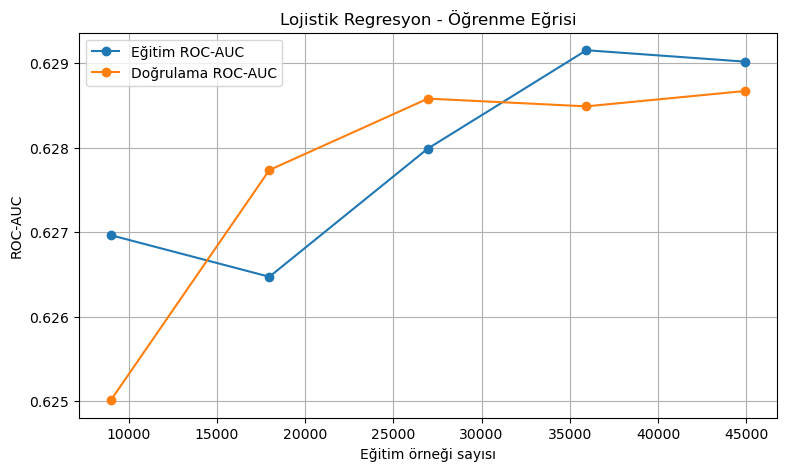

In [168]:

import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve, StratifiedKFold
import numpy as np

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

train_sizes, train_scores, validation_scores = learning_curve(
    estimator=application_model,
    X=X_app_train,
    y=y_app_train,
    train_sizes=np.linspace(0.2, 1.0, 5),
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

train_mean = train_scores.mean(axis=1)
validation_mean = validation_scores.mean(axis=1)

plt.figure(figsize=(9, 5))

plt.plot(
    train_sizes, train_mean,
    marker="o", label="Eğitim ROC-AUC"
)

plt.plot(
    train_sizes, validation_mean,
    marker="o", label="Doğrulama ROC-AUC"
)

plt.xlabel("Eğitim örneği sayısı")
plt.ylabel("ROC-AUC")
plt.title("Lojistik Regresyon - Öğrenme Eğrisi")
plt.legend()
plt.grid(True)
plt.show()


ROC-AUC: 0.6352

Sınıflandırma raporu:
              precision    recall  f1-score   support

           0       0.95      0.60      0.73     12922
           1       0.11      0.60      0.19      1118

    accuracy                           0.60     14040
   macro avg       0.53      0.60      0.46     14040
weighted avg       0.88      0.60      0.69     14040



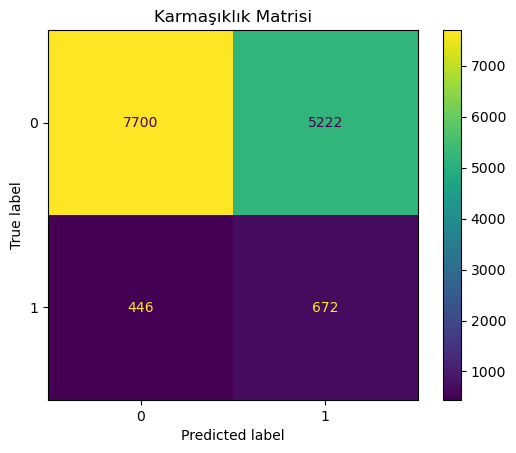

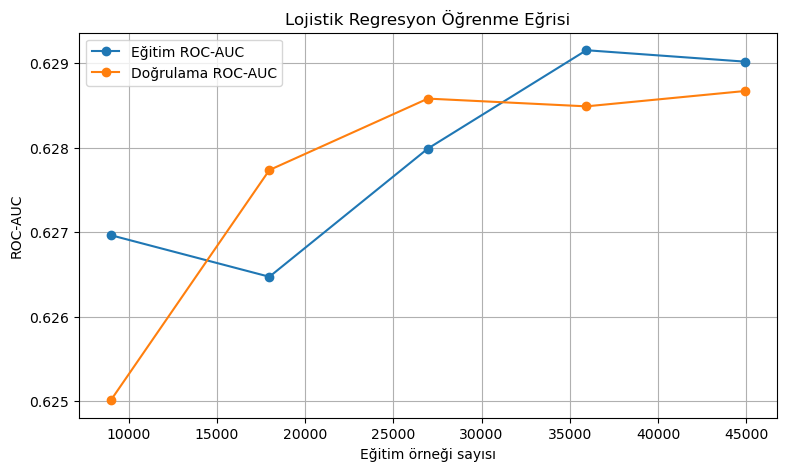


       KREDİ RİSK DEĞERLENDİRMESİ
Tahmini ödeme güçlüğü: %82.16
Risk seviyesi: 🔴 YÜKSEK RİSK
İşlem önerisi: Uzman incelemesi ve ikinci onay


In [170]:

from sklearn.metrics import (
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay
)

# 1. Başvuru sırasında kullanılacak temel özellikler
application_features = [
    "credit_income_ratio",
    "annuity_income_ratio",
    "age_years",
    "employment_years",
    "credit_goods_ratio",
    "income_per_person"
]

missing_columns = [
    col for col in application_features if col not in X.columns
]

if missing_columns:
    raise ValueError(f"Eksik sütunlar: {missing_columns}")

X_application = X[application_features].copy()

# Sonsuz değerleri eksik veriler
X_application = X_application.replace([np.inf, -np.inf], np.nan)

# 2. Eğitim ve test verileri ayır
X_app_train, X_app_test, y_app_train, y_app_test = train_test_split(
    X_application,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 3. Lojistik regresyon modeli
application_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

application_model.fit(X_app_train, y_app_train)

# 4. Test verisiyle değerlendirme
y_probability = application_model.predict_proba(X_app_test)[:, 1]
y_prediction = application_model.predict(X_app_test)

print("ROC-AUC:", round(
    roc_auc_score(y_app_test, y_probability), 4
))
print("\nSınıflandırma raporu:")
print(classification_report(y_app_test, y_prediction, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_app_test, y_prediction
)
plt.title("Karmaşıklık Matrisi")
plt.show()

# 5. Öğrenme eğrisi
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

train_sizes, train_scores, val_scores = learning_curve(
    estimator=application_model,
    X=X_app_train,
    y=y_app_train,
    train_sizes=np.linspace(0.2, 1.0, 5),
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

plt.figure(figsize=(9, 5))
plt.plot(
    train_sizes, train_scores.mean(axis=1),
    marker="o", label="Eğitim ROC-AUC"
)
plt.plot(
    train_sizes, val_scores.mean(axis=1),
    marker="o", label="Doğrulama ROC-AUC"
)
plt.xlabel("Eğitim örneği sayısı")
plt.ylabel("ROC-AUC")
plt.title("Lojistik Regresyon Öğrenme Eğrisi")
plt.legend()
plt.grid(True)
plt.show()

# 6. Müşteri risk değerlendirme fonksiyonu
def musteri_risk_tahmini(
    yas,
    calisma_yili,
    kredi_gelir_orani,
    taksit_gelir_orani,
    kredi_urun_orani,
    kisi_basi_gelir
):
    yeni_musteri = pd.DataFrame([{
        "credit_income_ratio": kredi_gelir_orani,
        "annuity_income_ratio": taksit_gelir_orani,
        "age_years": yas,
        "employment_years": calisma_yili,
        "credit_goods_ratio": kredi_urun_orani,
        "income_per_person": kisi_basi_gelir
    }])

    olasilik = application_model.predict_proba(
        yeni_musteri
    )[0, 1]

    risk_yuzdesi = olasilik * 100

    if risk_yuzdesi < 30:
        risk = "DÜŞÜK RİSK"
        prosedur = "Standart inceleme"
        renk = "🟢"

    elif risk_yuzdesi < 70:
        risk = "ORTA RİSK"
        prosedur = "Ek finansal değerlendirme"
        renk = "🟡"

    else:
        risk = "YÜKSEK RİSK"
        prosedur = "Uzman incelemesi ve ikinci onay"
        renk = "🔴"

    print("\n" + "=" * 42)
    print("       KREDİ RİSK DEĞERLENDİRMESİ")
    print("=" * 42)
    print(f"Tahmini ödeme güçlüğü: %{risk_yuzdesi:.2f}")
    print(f"Risk seviyesi: {renk} {risk}")
    print(f"İşlem önerisi: {prosedur}")
    print("=" * 42)

    return {
        "risk_olasiligi": round(risk_yuzdesi, 2),
        "risk_seviyesi": risk,
        "islem_onerisi": prosedur
    }

# 7. Örnek müşteriyle dene
sonuc = musteri_risk_tahmini(
    yas=24,
    calisma_yili=1,
    kredi_gelir_orani=9.0,
    taksit_gelir_orani=0.65,
    kredi_urun_orani=1.3,
    kisi_basi_gelir=30000
)
